# Geometry of Forgetting — colleague walkthrough (v2)

**Audience.** Researchers who have not seen this project or manifold-capacity methods.
**Goal.** After running top to bottom, you can explain the objects, the measurement, and the first findings — and point to a cell where each claim was computed.
**Venue status.** NeurReps was deferred for soundness; target is ICML (Jan 2027).

## 1. The question

Continual learning trains a network on a **sequence** of tasks. Accuracy on past tasks reports *how much* was lost. Representational similarity indices (e.g. CKA — centered kernel alignment) report *how far* the internal representation moved. Neither says **what** changed geometrically.

This project measures that. The instrument is **manifold capacity** (defined in §4): how many ways a linear readout could still split a set of class clouds. Capacity is decomposed into three geometric factors by an **exact identity** (defined in §5). The setting is a controlled synthetic stream; the scientific output is a measurement, not a new continual-learning algorithm.

**GLUE** (Geometry Linked to Untangling Efficiency; Chou et al.) is the parent method family for that decomposition; we implement the three-factor form in-house.

Prior context: modularity's benefit in continual learning was found to depend on how strongly features are learned ([arXiv:2606.17889](https://arxiv.org/abs/2606.17889)). That strength will be called $\gamma_0$ from §7 onward. Here the architecture is held fixed and the geometry is measured directly.


In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from scipy.optimize import linprog
from scipy.spatial.distance import pdist

plt.rcParams.update({
    "figure.dpi": 110,
    "font.size": 9,
    "axes.spines.top": False,
    "axes.spines.right": False,
})


def find_repo() -> Path:
    here = Path.cwd().resolve()
    candidates = [here, here.parent]
    if here.name == "notebooks":
        candidates.insert(0, here.parent)
    for cand in candidates:
        if (cand / "figures").is_dir() and (cand / "results").is_dir():
            return cand
    raise FileNotFoundError("run from repo root or notebooks/")


REPO = find_repo()
if str(REPO) not in sys.path:
    sys.path.insert(0, str(REPO))
print("repo:", REPO)


repo: C:\Users\kort\Documents\GeometryOfForgetting


## 2. Sixteen clouds

Inputs are **P = 16** point clouds (**manifolds**). Generator parameters (Chou et al., ICML 2025, App. D.1.1):

| symbol | meaning |
|---|---|
| $P$ | number of clouds (classes) |
| $M$ | points sampled per cloud |
| $d$ | ambient dimension of the input space |
| $D$ | intrinsic dimension of each cloud (how many directions it spreads) |
| $R$ | radius scale of each cloud (how fat it is) |

**Size** ($R$, $D$) and **position** (where the centre sits) are independent knobs. Capacity later attributes forgetting to related geometric properties, so the generator must not mix size into position.

Demo sizes below use smaller $M$ and $d$ than the trained runs so cells stay fast.


arrangement: (16, 20, 60)   (manifolds, points, ambient dim)
mean within-manifold radius : 0.966
mean between-centre distance: 1.416
ratio (size / separation)   : 0.682


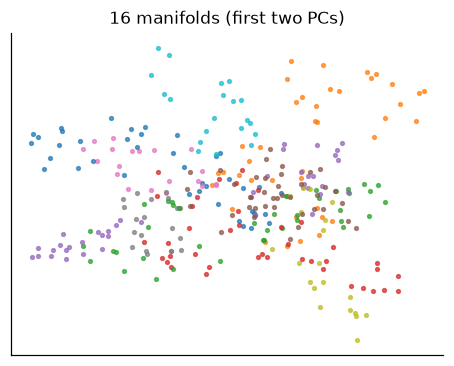

In [2]:
def make_arrangement(P=16, M=20, d=60, D=4, R=1.0, eps=1e-2, rho_C=0.0, rng=None):
    # Chou et al. ICML 2025 App. D.1.1 (pedagogical). Centre + R * unit spread + noise.
    # rho_C > 0 correlates centres via Cholesky of AR(1): C_ij = rho_C^{|i-j|}.
    rng = np.random.default_rng(0) if rng is None else rng
    centres = rng.normal(0, 1 / np.sqrt(d), (P, d))
    if rho_C > 0.0:
        idx = np.arange(P)
        cov = np.power(rho_C, np.abs(idx[:, None] - idx[None, :]))
        centres = np.linalg.cholesky(cov) @ centres
    out = np.empty((P, M, d))
    for i in range(P):
        axes = rng.normal(0, 1 / np.sqrt(d), (D, d))
        s = rng.normal(0, 1, (M, D))
        pre = s @ axes
        pre /= np.linalg.norm(pre, axis=1, keepdims=True)
        noise = rng.normal(0, 1 / np.sqrt(d), (M, d))
        out[i] = centres[i] + R * pre + eps * noise
    return out


def pca2(mans):
    Xall = mans.reshape(-1, mans.shape[-1])
    Xc = Xall - Xall.mean(0)
    _, _, Vt = np.linalg.svd(Xc, full_matrices=False)
    return (Xc @ Vt[:2].T).reshape(mans.shape[0], mans.shape[1], 2)


mans = make_arrangement(rng=np.random.default_rng(1))
print("arrangement:", mans.shape, "  (manifolds, points, ambient dim)")

centres = mans.mean(axis=1)
radius = np.linalg.norm(mans - centres[:, None], axis=2).mean(axis=1)
gaps = pdist(centres)
print(f"mean within-manifold radius : {radius.mean():.3f}")
print(f"mean between-centre distance: {gaps.mean():.3f}")
print(f"ratio (size / separation)   : {radius.mean() / gaps.mean():.3f}")

proj = pca2(mans)
fig, ax = plt.subplots(figsize=(4.2, 3.4))
for i in range(mans.shape[0]):
    ax.scatter(*proj[i].T, s=6, alpha=0.7)
ax.set_title("16 manifolds (first two PCs)")
ax.set_xticks([])
ax.set_yticks([])
plt.tight_layout()
plt.show()


## 3. A task is a labelling rule — and the stream has two knobs

A **task** paints eight clouds $+1$ and eight $-1$ (a **balanced dichotomy**: equal counts of each sign). The network learns to predict that paint.

The stream varies two things between consecutive tasks. Two similarity scores name them:

| score | symbol | meaning |
|---|---|---|
| **readout similarity** | $s_r$ | agreement of the two $\pm 1$ label vectors (Hamming-based; $s_r=1$ means identical rule up to a global sign flip) |
| **feature similarity** | $s_f$ | how correlated consecutive arrangements' **centres** are ($s_f$ near 1 = slow **drift**; near 0 = large **jump**) |

**Hamming distance** = number of clouds whose label differs between two tasks (always even for balanced dichotomies). At $P=16$, $s_r = 1 - 2h/P$, so Hamming $0 \to s_r=1$, Hamming $8 \to s_r=0$.

Centres can also be held **frozen** ($s_f=1$ exactly): used in a later Hamming arm; not in the registered 2×2.

> In the **registered** grid the clouds are **not** held fixed. Arrangements redraw with correlation $s_f$. “Same inputs, only the rule changes” is the frozen condition.

Hiratani (NeurIPS 2024) named a 2×2 of feature × readout similarity. On our grid the levels are effectively binary, so the honest rename is **task repetition × input change**. Corner codes below: first letter = feature/input (H=drift, L=jump), second = readout/rule (H=same, L=change) — e.g. **S-HL** = drift + changing rule.


task 0 labels: [-1 -1 -1  1 -1  1 -1 -1  1  1  1  1 -1  1  1 -1]
  Hamming  0 -> readout similarity 1.00
  Hamming  2 -> readout similarity 0.75
  Hamming  8 -> readout similarity 0.00


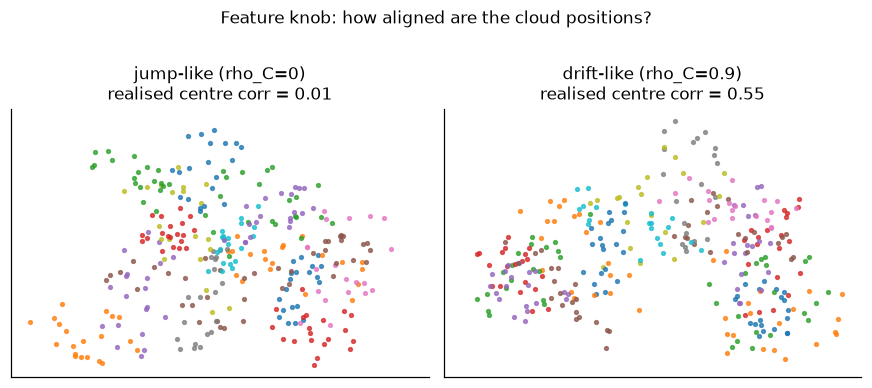

In [3]:
def balanced_dichotomy(P, rng):
    y = np.array([1] * (P // 2) + [-1] * (P // 2), dtype=np.int8)
    rng.shuffle(y)
    return y


def readout_similarity(y1, y2):
    # Sign-symmetric: a split and its complement are the same task.
    return abs(2 * np.mean(y1 == y2) - 1)


def at_hamming(y, h, rng):
    # New balanced split at Hamming distance h (swap h/2 of each side).
    y = y.copy()
    pos, neg = np.where(y > 0)[0], np.where(y < 0)[0]
    k = h // 2
    y[rng.choice(pos, k, replace=False)] = -1
    y[rng.choice(neg, k, replace=False)] = +1
    return y


def centre_corr(mans):
    S0 = mans.mean(axis=1)
    G = S0 @ S0.T
    norms = np.sqrt(np.diag(G))
    C = G / np.outer(norms, norms)
    off = ~np.eye(len(S0), dtype=bool)
    return float(C[off].mean())


def redraw_centres(mans, rho, rng):
    # Pedagogical stand-in for correlated redraw: blend old centres with a fresh draw.
    P, M, d = mans.shape
    old_c = mans.mean(axis=1)
    fresh = make_arrangement(P=P, M=M, d=d, rng=rng)
    new_c = rho * old_c + np.sqrt(max(1.0 - rho**2, 0.0)) * fresh.mean(axis=1)
    out = np.empty_like(mans)
    for i in range(P):
        local = mans[i] - old_c[i]
        out[i] = new_c[i] + local
    return out


r = np.random.default_rng(3)
y0 = balanced_dichotomy(16, r)
print("task 0 labels:", y0)
for h in [0, 2, 8]:
    y = y0 if h == 0 else at_hamming(y0, h, r)
    print(f"  Hamming {h:2d} -> readout similarity {readout_similarity(y0, y):.2f}")

# Show feature similarity: two arrangements
fig, ax = plt.subplots(1, 2, figsize=(8, 3.4), sharex=True, sharey=True)
for a, rho, title in zip(ax, (0.0, 0.9), ("jump-like (rho_C=0)", "drift-like (rho_C=0.9)")):
    m = make_arrangement(rho_C=rho, rng=np.random.default_rng(7))
    proj = pca2(m)
    for i in range(m.shape[0]):
        a.scatter(*proj[i].T, s=6, alpha=0.75)
    a.set_title(f"{title}\nrealised centre corr = {centre_corr(m):.2f}")
    a.set_xticks([])
    a.set_yticks([])
plt.suptitle("Feature knob: how aligned are the cloud positions?", y=1.02)
plt.tight_layout()
plt.show()


### Live cartoon of the registered 2×2

Each row is one stream corner (S-HH / S-LH / S-HL / S-LL as above). Columns are tasks $t=0,1,2$. Colour = current rule ($+1$ blue, $-1$ orange). Position shifts = input motion. Notes on the right preview later results; ignore $\gamma$ / “decorrelate” until §7–§8 if those words are new.


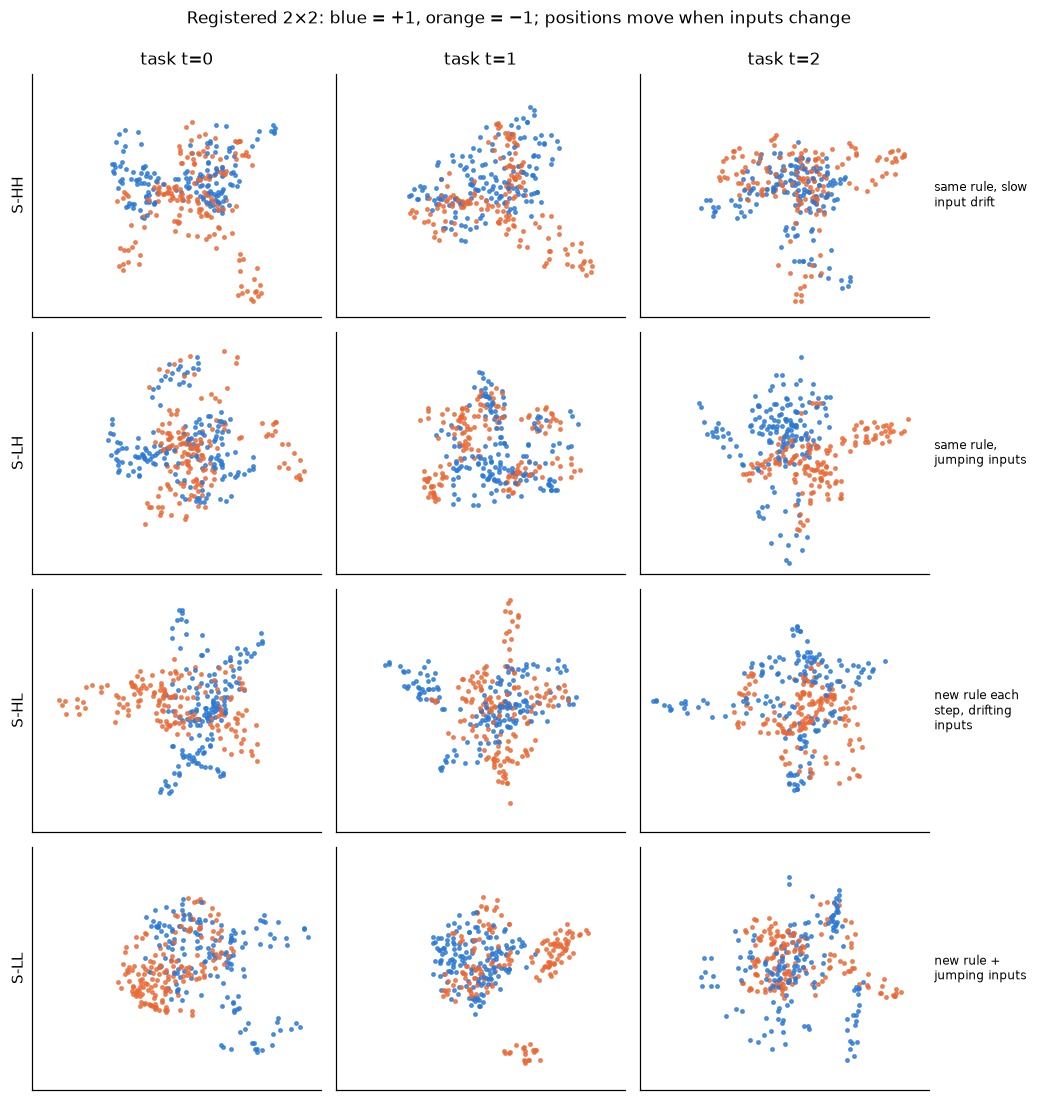

Plain-language grid
                          drifting inputs     jumping inputs
same rule                            S-HH               S-LH
changing rule                        S-HL               S-LL


In [4]:
CORNERS = {
    "S-HH": dict(rule="same", motion="drift", note="same rule, slow input drift"),
    "S-LH": dict(rule="same", motion="jump", note="same rule, jumping inputs"),
    "S-HL": dict(rule="change", motion="drift", note="new rule each step, drifting inputs"),
    "S-LL": dict(rule="change", motion="jump", note="new rule + jumping inputs"),
}

rho_motion = {"drift": 0.9, "jump": 0.1, "frozen": 1.0}


def stream_frames(rule, motion, seed=0):
    rng = np.random.default_rng(seed)
    y = balanced_dichotomy(16, rng)
    frames = []
    m = make_arrangement(rng=rng)
    for t in range(3):
        if t > 0:
            if motion != "frozen":
                m = redraw_centres(m, rho_motion[motion], rng)
            if rule == "change":
                y = at_hamming(y, 8, rng)  # orthogonal step at P=16
        frames.append((m.copy(), y.copy()))
    return frames


fig, axes = plt.subplots(4, 3, figsize=(9.5, 10), sharex=True, sharey=True)
for row, (name, spec) in enumerate(CORNERS.items()):
    frames = stream_frames(spec["rule"], spec["motion"], seed=10 + row)
    for col, (m, y) in enumerate(frames):
        ax = axes[row, col]
        proj = pca2(m)
        for i in range(m.shape[0]):
            ax.scatter(
                *proj[i].T, s=5, alpha=0.75,
                color="#2a78d6" if y[i] > 0 else "#eb6834",
            )
        if row == 0:
            ax.set_title(f"task t={col}")
        if col == 0:
            ax.set_ylabel(name, fontsize=10)
        ax.set_xticks([])
        ax.set_yticks([])
    axes[row, 2].text(
        1.02, 0.5, spec["note"], transform=axes[row, 2].transAxes,
        va="center", ha="left", fontsize=8, wrap=True,
    )
plt.suptitle("Registered 2×2: blue = +1, orange = −1; positions move when inputs change", y=0.995)
plt.tight_layout()
plt.show()

print("Plain-language grid")
print(f"{'':22} {'drifting inputs':>18} {'jumping inputs':>18}")
print(f"{'same rule':22} {'S-HH':>18} {'S-LH':>18}")
print(f"{'changing rule':22} {'S-HL':>18} {'S-LL':>18}")


### Cliff vs dose on the rule axis

If interference scaled smoothly with “how different the new rule is,” the drop in
separability of the *first* task would fall gradually with Hamming distance /
$s_r$. A follow-up **Hamming arm** crosses input regime (frozen / drift / jump)
with several $s_r$ values.

The plot below uses production summary numbers. Two terms appear here slightly
early (full definitions in §4 and §8):

- $\alpha$ — manifold capacity (higher = more separable); $\Delta\log\alpha < 0$ means the first task got harder to read linearly.
- **floors** — that change in units of the estimator's own noise (so “flat” means below noise, not “a small decimal”).
- $\gamma$ — feature-learning strength (lazy ≪ 1, rich ≫ 1); formal sweep in §7.

**Jump** is about inputs. **Cliff** is about the rule. They are different axes:
almost all of the loss appears as soon as the rule is no longer identical — a
**cliff** — except under drift, where a graded **dose** appears after the cliff.


Change in capacity of task 0 after later tasks (summary from results/hamming_slice.json)
Units: estimator noise floors. Negative = first task harder to separate.

gamma input     s_r=1.0 s_r=0.75  s_r=0.5 s_r=0.25   cliff  post-range
   10 frozen        7.1    -68.2    -69.1    -68.9    75.3     0.7 
   10 drift         6.7    -61.3    -70.3    -74.6    68.0    13.3   (post-cliff resolved)
   10 jump        -55.1    -76.9    -78.0    -77.6    21.8     0.7 
    1 frozen        1.0    -34.0    -34.0    -34.4    35.0     0.4 
    1 drift        12.7    -23.7    -33.3    -33.7    36.4    10.0   (post-cliff resolved)
    1 jump        -14.0    -26.3    -29.5    -28.8    12.3     2.5 


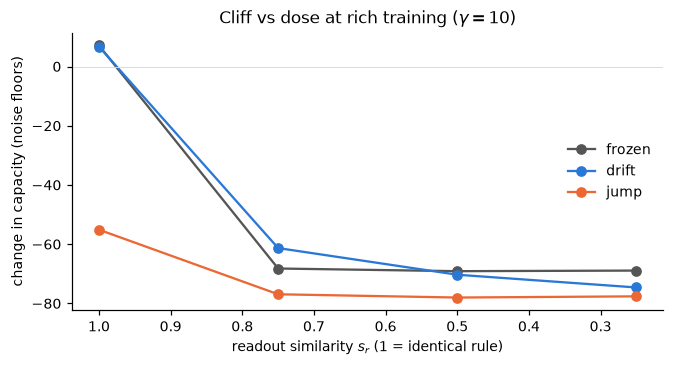


Read: frozen/jump — step from s_r=1 to 0.75, then flat (cliff).
      drift — cliff plus further drop from 0.75 to 0.25 (dose).
      jump at s_r=1 already largely negative (same rule, new inputs).


In [5]:
ham = json.loads((REPO / "results/hamming_slice.json").read_text())
cap = ham["structure"]["capacity"]

print("Change in capacity of task 0 after later tasks (summary from results/hamming_slice.json)")
print("Units: estimator noise floors. Negative = first task harder to separate.")
print()
sr_levels = ["1.0", "0.75", "0.5", "0.25"]
print(f"{'gamma':>5} {'input':<8}", " ".join(f"{'s_r='+s:>8}" for s in sr_levels), "  cliff  post-range")
for g in (10, 1):
    for motion in ("frozen", "drift", "jump"):
        cell = cap[f"gamma={g}|{motion}"]
        floors = [cell["floors_1dp"][s] for s in sr_levels]
        print(
            f"{g:5d} {motion:<8}",
            " ".join(f"{v:8.1f}" for v in floors),
            f"  {cell['cliff']:5.1f}  {cell['post_range']:6.1f}",
            "" if cell["post_ci_overlap"] else "  (post-cliff resolved)",
        )

fig, ax = plt.subplots(figsize=(6.2, 3.4))
x = [float(s) for s in sr_levels]
for motion, color in (("frozen", "#555555"), ("drift", "#2a78d6"), ("jump", "#eb6834")):
    cell = cap["gamma=10|" + motion]
    y = [cell["floors_1dp"][s] for s in sr_levels]
    ax.plot(x, y, "o-", color=color, label=motion)
ax.axhline(0, color="0.85", lw=0.6)
ax.set_xlabel(r"readout similarity $s_r$ (1 = identical rule)")
ax.set_ylabel(r"change in capacity (noise floors)")
ax.set_title(r"Cliff vs dose at rich training ($\gamma=10$)")
ax.invert_xaxis()
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

print()
print("Read: frozen/jump — step from s_r=1 to 0.75, then flat (cliff).")
print("      drift — cliff plus further drop from 0.75 to 0.25 (dose).")
print("      jump at s_r=1 already largely negative (same rule, new inputs).")


## 4. What capacity is

**Manifold capacity** asks: given these clouds, how many different two-way splits could a *linear* readout still separate? It is not accuracy and not CKA.

Operational demo: project into $n$ random dimensions; test linear separability with an LP; bisect to find $N_{\mathrm{crit}}$ where success rate crosses $1/2$; report $\alpha = P / N_{\mathrm{crit}}$.

This pedagogical estimator is intentionally tiny. The paper uses the joint-QP GLUE core (`src/glue/core.py`). Both answer the same conceptual question.


In [6]:
def separable(X, labels):
    # Feasibility: exists w with labels_i * <w, x_i> >= 1 for all i.
    A_ub = -(labels[:, None] * X)
    b_ub = -np.ones(len(X))
    res = linprog(
        np.zeros(X.shape[1]), A_ub=A_ub, b_ub=b_ub,
        bounds=[(None, None)] * X.shape[1], method="highs",
    )
    return res.status == 0


def frac_separable(mans, n, rng, n_dich=6, n_proj=3, y=None):
    P, M, d = mans.shape
    X = mans.reshape(P * M, d)
    hits = tot = 0
    n_loop = 1 if y is not None else n_dich
    for _ in range(n_loop):
        lab_p = y if y is not None else balanced_dichotomy(P, rng)
        lab = np.repeat(lab_p, M)
        for _ in range(n_proj):
            W = rng.normal(size=(d, n)) / np.sqrt(d)
            hits += int(separable(X @ W, lab))
            tot += 1
    return hits / tot


def capacity(mans, rng, **kw):
    # alpha = P / N_crit by bisection on projection dimension.
    P, M, d = mans.shape
    lo, hi = 1, d
    while lo < hi:
        mid = (lo + hi) // 2
        if frac_separable(mans, mid, rng, **kw) >= 0.5:
            hi = mid
        else:
            lo = mid + 1
    return P / lo, lo


rng = np.random.default_rng(0)
rows = []
for R in [0.5, 1.0, 2.0]:
    a, nc = capacity(make_arrangement(R=R, rng=np.random.default_rng(1)), rng)
    rows.append(("radius", R, a, nc))
for D in [2, 4, 8]:
    a, nc = capacity(make_arrangement(D=D, rng=np.random.default_rng(1)), rng)
    rows.append(("dimension", D, a, nc))

print(f"{'knob':<10}{'value':>7}{'capacity':>11}{'N_crit':>8}")
for k, v, a, nc in rows:
    print(f"{k:<10}{v:>7g}{a:>11.3f}{nc:>8}")

m = make_arrangement(rng=np.random.default_rng(1))
split_rng = np.random.default_rng(11)
print()
print("Same clouds. Different questions. Different answers.")
print(f"{'split':<16}{'capacity':>11}{'N_crit':>8}")
ys = {}
for name in ("split A", "split B"):
    y = balanced_dichotomy(16, split_rng)
    ys[name] = y
    a, nc = capacity(m, rng, y=y)
    print(f"{name:<16}{a:>11.3f}{nc:>8}")
print("readout similarity A vs B:",
      f"{readout_similarity(ys['split A'], ys['split B']):.2f}")


knob        value   capacity  N_crit
radius        0.5      0.800      20
radius          1      0.471      34
radius          2      0.333      48
dimension       2      0.640      25
dimension       4      0.500      32
dimension       8      0.410      39

Same clouds. Different questions. Different answers.
split              capacity  N_crit


split A               0.410      39


split B               0.533      30
readout similarity A vs B: 0.25


Fatter or higher-dimensional clouds raise $N_{\mathrm{crit}}$ → capacity falls. Two different splits on the **same** clouds can have different capacities: capacity is a property of (representation, question), not of the representation alone. That fact is what makes **generic vs retained** meaningful.


## 5. The three-factor identity

Chou et al. (ICLR 2026): capacity factors exactly as

$$
\alpha = \Psi_{\mathrm{eff}}\cdot\frac{1+R_{\mathrm{eff}}^{-2}}{D_{\mathrm{eff}}}
$$

| factor | symbol | meaning |
|---|---|---|
| effective utility | $\Psi_{\mathrm{eff}}$ | how well the geometry aligns with the labels being asked |
| effective radius | $R_{\mathrm{eff}}$ | cloud size relative to separation (**not** the generator knob $R$ from §2) |
| effective dimension | $D_{\mathrm{eff}}$ | how many directions the clouds spread in (**not** the generator knob $D$) |

A change in $\alpha$ therefore splits with **zero residual**:

$$
\Delta\log\alpha
= \underbrace{\Delta\log\Psi_{\mathrm{eff}}}_{\text{utility}}
+ \underbrace{\Delta\log(1+R_{\mathrm{eff}}^{-2})}_{\text{radius}}
- \underbrace{\Delta\log D_{\mathrm{eff}}}_{\text{dimension}}
$$

A **share** of a change is $|$term$|$ divided by the sum of the three absolute terms.

Below: (i) verify the identity on a published summary file (always in git);
(ii) if the package imports, run a tiny live measurement on toy manifolds.


In [7]:
FACTORS = ("utility", "radius", "dimension")
MIN_FLOORS = 2.0


def load_sidecar(pattern: str) -> dict:
    hits = sorted((REPO / "figures").glob(pattern))
    if not hits:
        raise FileNotFoundError(pattern)
    return json.loads(hits[-1].read_text())


fig2 = load_sidecar("fig2_gamma_sweep__forgetting__lag12__*.json")
row = fig2["data"]["10.0"]
terms = row["terms"]
lhs = row["dlog_alpha"]
rhs = sum(terms[k] for k in FACTORS)
print("From figures/fig2_...forgetting...lag12 (rich training; average over the three")
print("stream corners that *lose* capacity — see Finding A for why S-HH is held out)")
print(f"  Δ log α measured : {lhs:+.12f}")
print(f"  sum of 3 terms   : {rhs:+.12f}")
print(f"  residual         : {lhs - rhs:.2e}")
print()
mag = {k: abs(terms[k]) for k in FACTORS}
total = sum(mag.values())
print(f"{'channel':<12}{'term':>14}{'share':>10}")
for k in FACTORS:
    print(f"  {k:<10}{terms[k]:+14.6f}{mag[k] / total:10.3f}")
print()
print("On this cell utility carries "
      f"{100 * mag['utility'] / total:.0f}% of the |motion|.")


From figures/fig2_...forgetting...lag12 (rich training; average over the three
stream corners that *lose* capacity — see Finding A for why S-HH is held out)
  Δ log α measured : -1.291678074917
  sum of 3 terms   : -1.291678074917
  residual         : -2.22e-16

channel               term     share
  utility        -0.580203     0.449
  radius         -0.147313     0.114
  dimension      -0.564162     0.437

On this cell utility carries 45% of the |motion|.


In [8]:
# Optional live GLUE-core demo (small P, small n_t). Skips cleanly if deps missing.
try:
    from src.glue.core import Ensemble, from_arrangement, glue_measures
    from src.manifolds.generator import make_arrangement as repo_make_arrangement
    from src.manifolds.dichotomies import sample_balanced

    rng = np.random.default_rng(0)
    arr0 = repo_make_arrangement(P=8, d=40, D=2, R=0.8, M=40, rng=rng)
    arr1 = repo_make_arrangement(P=8, d=40, D=2, R=1.6, M=40, rng=rng)  # fatter
    y = sample_balanced(8, rng).astype(np.float64)
    ens = Ensemble(kind="retained", y_ref=y)

    def measure(arr):
        return glue_measures(
            from_arrangement(arr.points),
            np.random.default_rng(1),
            n_t=30,
            ensemble=ens,
        )

    g0, g1 = measure(arr0), measure(arr1)
    print("Live glue_core on toy manifolds (retained, P=8, n_t=30)")
    print(f"{'':>10}{'alpha':>10}{'Psi':>10}{'R':>10}{'D':>10}{'id_resid':>12}")
    for name, g in (("R=0.8", g0), ("R=1.6", g1)):
        print(f"{name:>10}{g.alpha:10.4f}{g.Psi_eff:10.4f}{g.R_eff:10.4f}"
              f"{g.D_eff:10.4f}{g.identity_residual:12.2e}")

    lhs = np.log(g1.alpha / g0.alpha)
    d_psi = np.log(g1.Psi_eff / g0.Psi_eff)
    d_rad = np.log((1 + g1.R_eff**-2) / (1 + g0.R_eff**-2))
    d_dim = -np.log(g1.D_eff / g0.D_eff)
    print()
    print(f"Δ log α measured : {lhs:+.6f}")
    print(f"         summed  : {d_psi + d_rad + d_dim:+.6f}")
    print(f"         residual: {lhs - (d_psi + d_rad + d_dim):.2e}")
except Exception as exc:
    print("Live glue_core demo skipped:", type(exc).__name__, "-", exc)
    print("Sidecar identity check above is sufficient for the walkthrough.")


Live glue_core on toy manifolds (retained, P=8, n_t=30)
               alpha       Psi         R         D    id_resid
     R=0.8    0.8430    0.7480    1.0240    1.7336    0.00e+00
     R=1.6    0.5132    0.7139    1.5382    1.9793    0.00e+00

Δ log α measured : -0.496366
         summed  : -0.496366
         residual: 1.67e-16


## 6. Generic vs retained

- **Generic capacity** — average capacity over random balanced splits (option value for future questions).
- **Retained capacity** — capacity for one **fixed** past split.

In a sequence, retained capacity of an earlier task is what this project calls geometric forgetting when it falls.


In [9]:
m = make_arrangement(rng=np.random.default_rng(1))
split_rng = np.random.default_rng(11)
print(f"{'split':<12}{'capacity':>11}{'N_crit':>8}")
alphas = []
for i in range(5):
    y = balanced_dichotomy(16, split_rng)
    a, nc = capacity(m, rng, y=y)
    alphas.append(a)
    print(f"{'split ' + str(i):<12}{a:>11.3f}{nc:>8}")

# Pedagogical mean. The production pipeline aggregates per-manifold α by harmonic mean.
generic = float(np.mean(alphas))
retained = alphas[0]
print()
print(f"{'generic':<12}{generic:>11.3f}   (arithmetic mean over five splits — demo only)")
print(f"{'retained':<12}{retained:>11.3f}   (split 0 held fixed)")
print()
print("Two questions on the same clouds, not two training runs.")


split          capacity  N_crit


split 0           0.444      36


split 1           0.516      31


split 2           0.457      35


split 3           0.516      31


split 4           0.500      32

generic           0.487   (arithmetic mean over five splits — demo only)
retained          0.444   (split 0 held fixed)

Two questions on the same clouds, not two training runs.


## 7. What was run (production)

| property | choice |
|---|---|
| network | one hidden **ReLU** layer; width 300 in each of two identical halves (**modules** A and B) that sum into one shared scalar readout |
| optimiser / loss | full-batch gradient descent on mean squared error to targets $\pm 1$ |
| parameterisation | **μP** (maximal update parameterisation of Graldi et al.): sets how learning rate and output scale depend on width and on $\gamma_0$ |
| stopping | train each task until loss $\le 0.05$ (matched loss, not matched step count — rich arms finish in fewer steps) |
| stream | $T=16$ tasks; the 2×2 of §3 |
| $\gamma_0$ | feature-learning strength $\{0.03,0.1,0.3,1,3,10\}$ (small ≈ lazy / kernel-like; large ≈ rich / features move) |
| primary cell | retained capacity of **task 0** at **lag 12** (lag = number of task boundaries since that task was learned) |
| sampling | unique $n=8$ independent (arrangement, initialisation) draws per reported cell |

Not claimed here: heterogeneous modules, CIFAR, depth as primary, second-learner generalisation.


## 8. First findings

How to read this section. Each finding has (1) plain-language setup, (2) a table
computed from stored result files, (3) figures drawn from **those same numbers**.
A **floor** is the estimator's own Monte-Carlo noise: re-measure one fixed
trained representation under several measurement seeds. Magnitudes are in units
of that floor so "unchanged" means below noise, not "a small number."
A change is **resolvable** when $|\Delta\log\alpha|$ clears two floors.

Primary cell everywhere unless noted: **task 0**, **lag 12** (twelve tasks
later), **module A**, unique $n=8$ arrangement draws.


### Finding A — When capacity is *lost*, richness changes *how* it is lost

**What is being measured.** After the network finishes task 0, we record retained
capacity of that same labelling rule. Twelve tasks later we measure it again.
$\Delta\log\alpha < 0$ means the old rule is harder for a linear readout to
separate — geometric forgetting.

**What the three channels mean (plain language).**
Because $\Delta\log\alpha$ splits exactly into three terms:

| channel | symbol | intuition |
|---|---|---|
| **utility** | $\Delta\log\Psi_{\mathrm{eff}}$ | Did the representation stay *aligned* with the old labels? |
| **radius** | $\Delta\log(1+R_{\mathrm{eff}}^{-2})$ | Did the class clouds inflate (or centres collapse) relative to their separation? |
| **dimension** | $-\Delta\log D_{\mathrm{eff}}$ | Did the clouds spread into more effective directions? |

A **share** is $|$term$|$ / sum of the three absolute terms: which channel carried
how much of the motion, ignoring sign.

**Pool caveat — say this before the figure.** The headline curve is **not** an
average over all four stream corners. It pools only the three corners that
*lose* retained capacity: **S-HL ∪ S-LH ∪ S-LL**. S-HH (the gaining corner) is
held out on purpose. That pool still mixes mechanisms: S-LH keeps the same rule
but jumps the inputs; S-HL/S-LL change the rule. Finding A answers: *when
capacity falls, how does the channel mix depend on feature-learning strength
$\gamma_0$?* It does **not** say every stream forgets the same way.


FINDING A — three-corner FORGETTING pool (S-HL + S-LH + S-LL)
task 0, lag 12, module A | unique n = 8

  gamma   floors  status          utility   radius dimension
   0.03     -0.2  below floor           —        —        —
    0.1     -2.1  resolvable        0.083    0.387    0.530
    0.3    -10.0  resolvable        0.189    0.368    0.443
      1    -26.2  resolvable        0.332    0.246    0.421
      3    -45.3  resolvable        0.414    0.150    0.436
     10    -69.7  resolvable        0.449    0.114    0.437

Read the table:
  gamma=0.03:  |floors|<2  -> nothing resolvable (lazy network barely moves).
  gamma=0.1 :  first resolvable loss (~2 floors).
  gamma=10  :  ~70 floors lost; utility share ~0.45, radius share ~0.11.
  From gamma~0.3 onward the reorganisation is mostly utility UP, radius DOWN.

Hidden by the pool (same gamma=10, same-rule corners only):
  pool (three loss corners): -69.7 floors
  S-HH drift + same rule:    +6.2 floors  (GAIN)
  S-LH jump  + same rule:   

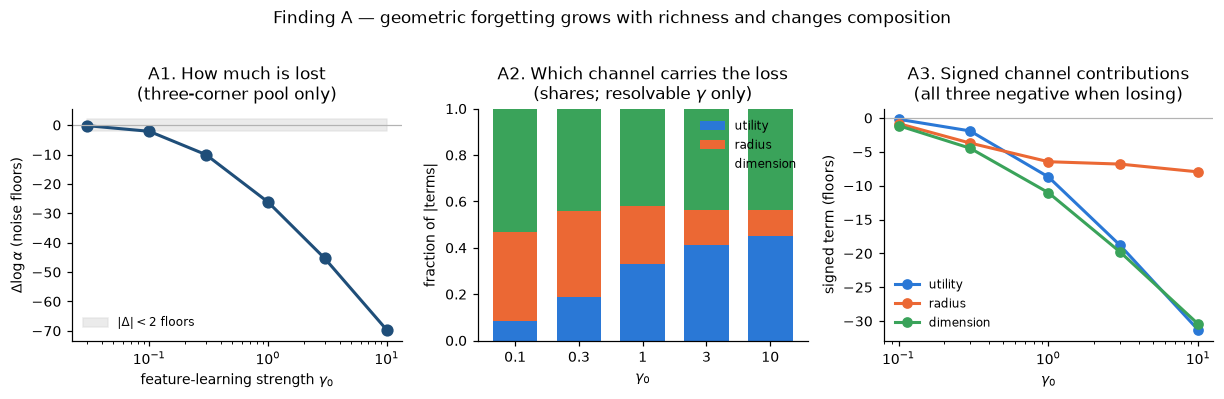

In [10]:
u8 = json.loads((REPO / "results/unique_n8.json").read_text())
N_UNIQUE = u8["unique_seeds_per_cell"]
fig2_shh = load_sidecar("fig2_gamma_sweep__S-HH__lag12__*.json")
COLOURS = {"utility": "#2a78d6", "radius": "#eb6834", "dimension": "#3aa35a"}

print("=" * 72)
print("FINDING A — three-corner FORGETTING pool (S-HL + S-LH + S-LL)")
print(f"task 0, lag 12, module A | unique n = {N_UNIQUE}")
print("=" * 72)
print()
print(f"{'gamma':>7} {'floors':>8}  {'status':<14} "
      f"{'utility':>8} {'radius':>8} {'dimension':>8}")
rows_f1 = []
for g in sorted(fig2["data"], key=float):
    row = fig2["data"][g]
    fl = row["floors_signed"]
    resolved = abs(fl) >= MIN_FLOORS
    sh = row["shares"] if resolved else None
    status = "resolvable" if resolved else "below floor"
    if sh is None:
        u_s = r_s = d_s = "—"
    else:
        u_s, r_s, d_s = f"{sh['utility']:.3f}", f"{sh['radius']:.3f}", f"{sh['dimension']:.3f}"
    print(f"{float(g):7g} {fl:8.1f}  {status:<14} {u_s:>8} {r_s:>8} {d_s:>8}")
    rows_f1.append((float(g), fl, sh, row))

print()
print("Read the table:")
print("  gamma=0.03:  |floors|<2  -> nothing resolvable (lazy network barely moves).")
print("  gamma=0.1 :  first resolvable loss (~2 floors).")
print("  gamma=10  :  ~70 floors lost; utility share ~0.45, radius share ~0.11.")
print("  From gamma~0.3 onward the reorganisation is mostly utility UP, radius DOWN.")
print()
print("Hidden by the pool (same gamma=10, same-rule corners only):")
print(f"  pool (three loss corners): {fig2['data']['10.0']['floors_signed']:+.1f} floors")
print(f"  S-HH drift + same rule:    {fig2_shh['data']['10.0']['floors_signed']:+.1f} floors  (GAIN)")
print("  S-LH jump  + same rule:    -55.8 floors  (docs/20; domain shift with fixed task)")

gammas = [g for g, _, _, _ in rows_f1]
floors = [fl for _, fl, _, _ in rows_f1]
resolved = [(g, sh, row) for g, fl, sh, row in rows_f1 if sh is not None]
g_r = [g for g, _, _ in resolved]

fig, axes = plt.subplots(1, 3, figsize=(11.2, 3.5))

# Panel 1 — magnitude
ax = axes[0]
ax.plot(gammas, floors, "o-", color="#1f4e79", lw=2, ms=7)
ax.fill_between(gammas, -MIN_FLOORS, MIN_FLOORS, color="0.85", alpha=0.5, label=r"$|\Delta|<2$ floors")
ax.axhline(0, color="0.7", lw=0.8)
ax.set_xscale("log")
ax.set_xlabel(r"feature-learning strength $\gamma_0$")
ax.set_ylabel(r"$\Delta\log\alpha$ (noise floors)")
ax.set_title("A1. How much is lost\n(three-corner pool only)")
ax.legend(frameon=False, fontsize=8)

# Panel 2 — stacked shares
ax = axes[1]
bottom = np.zeros(len(g_r))
xlabels = [f"{g:g}" for g in g_r]
for k in FACTORS:
    vals = np.array([sh[k] for _, sh, _ in resolved])
    ax.bar(xlabels, vals, bottom=bottom, color=COLOURS[k], label=k, width=0.7)
    bottom += vals
ax.set_ylim(0, 1)
ax.set_xlabel(r"$\gamma_0$")
ax.set_ylabel("fraction of $|$terms$|$")
ax.set_title("A2. Which channel carries the loss\n(shares; resolvable $\gamma$ only)")
ax.legend(frameon=False, loc="upper right", fontsize=8)

# Panel 3 — signed terms in floors (so signs are visible)
ax = axes[2]
# convert log terms to floor units using each row's floors / dlog_alpha scale
for k in FACTORS:
    vals = []
    for g, sh, row in resolved:
        scale = row["floors_signed"] / row["dlog_alpha"] if row["dlog_alpha"] != 0 else 0.0
        vals.append(row["terms"][k] * scale)
    ax.plot(g_r, vals, "o-", color=COLOURS[k], label=k, lw=2, ms=6)
ax.axhline(0, color="0.7", lw=0.8)
ax.set_xscale("log")
ax.set_xlabel(r"$\gamma_0$")
ax.set_ylabel("signed term (floors)")
ax.set_title("A3. Signed channel contributions\n(all three negative when losing)")
ax.legend(frameon=False, fontsize=8)

fig.suptitle(
    "Finding A — geometric forgetting grows with richness and changes composition",
    fontsize=11, y=1.02,
)
plt.tight_layout()
plt.show()


**Takeaway for Finding A.** Lazy training ($\gamma_0\lesssim 0.03$) does not
measurably forget in this geometry. As $\gamma_0$ rises, forgetting becomes
huge (~70 floors at $\gamma_0=10$), and the **mix** shifts: intermediate richness
loses capacity mainly because clouds inflate relative to separation (radius);
rich training loses it mainly because alignment with the old labels degrades
(utility). Dimension stays a large share throughout. Lazy and rich forgetting
are not the same process at different intensities.


### Finding B — One corner *gains* capacity; that is not forgetting with a minus sign

**Setup.** Hold the labelling rule fixed (every task uses $y_0$) and let the
inputs **drift** slowly — that is corner **S-HH**. Retained capacity of task 0
is measured again at lag 12.

**Claim.** S-HH does not merely forget less. Retained capacity **rises**
(positive $\Delta\log\alpha$). Behavioural forgetting on that corner is ~0.
Across 520 design cells (richness × condition × width × task × lag probes),
every *resolvable* capacity gain is an S-HH cell; the largest gain elsewhere
is 0.74 floors (below the two-floor gate).

**Why this is not a sign flip of Finding A.** Look at which channels move.
In the three-corner *loss* pool at rich $\gamma$, all three terms are negative
and radius is a real cost. In S-HH the gain is carried by **utility** and
**dimension** (both improving capacity); the radius term sits near or below the
resolution gate. So gain and loss are different geometric recipes, not one
quantity with two signs.

**Same-rule contrast (preview of stream structure).** Keep the rule fixed and
only change how inputs move: **drift (S-HH) → gain**, **jump (S-LH) → large
loss** (−55.8 floors at $\gamma=10$). That is domain shift with a fixed task —
not interference from other labelling rules.


FINDING B — S-HH gain vs three-corner loss

  gamma       S-HH S-HH status          pool pool status   
   0.03       +0.8 below floor          -0.2 below floor   
    0.1       +4.5 resolvable           -2.1 resolvable    
    0.3       +9.3 resolvable          -10.0 resolvable    
      1      +11.8 resolvable          -26.2 resolvable    
      3      +10.9 resolvable          -45.3 resolvable    
     10       +6.2 resolvable          -69.7 resolvable    

resolvable S-HH cells that GAIN: 5/5

Channel recipe at gamma=10 (signed terms in log units):
channel         loss pool    S-HH gain
utility           -0.5802      +0.0553
radius            -0.1473      -0.0124
dimension         -0.5642      +0.0712

S-HH shares of |motion| at gamma=10: {'utility': 0.398, 'radius': 0.089, 'dimension': 0.513}
  (radius share is small; radius term is near the resolution gate)


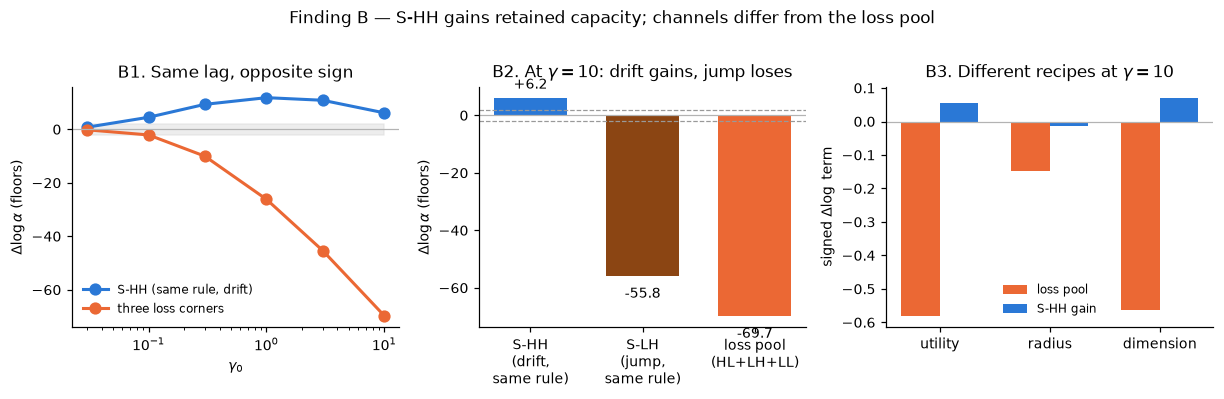

In [11]:
print("=" * 72)
print("FINDING B — S-HH gain vs three-corner loss")
print("=" * 72)
print()
print(f"{'gamma':>7} {'S-HH':>10} {'S-HH status':<14} {'pool':>10} {'pool status':<14}")
n_gain = n_gain_res = 0
for g in sorted(fig2["data"], key=float):
    gain = fig2_shh["data"][g]
    loss = fig2["data"][g]
    g_ok = abs(gain["floors_signed"]) >= MIN_FLOORS
    l_ok = abs(loss["floors_signed"]) >= MIN_FLOORS
    g_st = "resolvable" if g_ok else "below floor"
    l_st = "resolvable" if l_ok else "below floor"
    print(f"{float(g):7g} {gain['floors_signed']:+10.1f} {g_st:<14} "
          f"{loss['floors_signed']:+10.1f} {l_st:<14}")
    if g_ok:
        n_gain_res += 1
        if gain["floors_signed"] > 0:
            n_gain += 1

print(f"\nresolvable S-HH cells that GAIN: {n_gain}/{n_gain_res}")

# Channel recipe at gamma=10: loss pool vs S-HH gain
loss10 = fig2["data"]["10.0"]
gain10 = fig2_shh["data"]["10.0"]
print()
print("Channel recipe at gamma=10 (signed terms in log units):")
print(f"{'channel':<12} {'loss pool':>12} {'S-HH gain':>12}")
for k in FACTORS:
    print(f"{k:<12} {loss10['terms'][k]:+12.4f} {gain10['terms'][k]:+12.4f}")
print()
print("S-HH shares of |motion| at gamma=10:",
      {k: round(gain10["shares"][k], 3) for k in FACTORS})
print("  (radius share is small; radius term is near the resolution gate)")

keys = sorted(fig2["data"], key=float)
g_all = [float(k) for k in keys]

fig, axes = plt.subplots(1, 3, figsize=(11.2, 3.5))

# B1 — opposite signs across gamma
ax = axes[0]
ax.plot(g_all, [fig2_shh["data"][k]["floors_signed"] for k in keys],
        "o-", color="#2a78d6", lw=2, ms=7, label="S-HH (same rule, drift)")
ax.plot(g_all, [fig2["data"][k]["floors_signed"] for k in keys],
        "o-", color="#eb6834", lw=2, ms=7, label="three loss corners")
ax.fill_between(g_all, -MIN_FLOORS, MIN_FLOORS, color="0.85", alpha=0.45)
ax.axhline(0, color="0.7", lw=0.8)
ax.set_xscale("log")
ax.set_xlabel(r"$\gamma_0$")
ax.set_ylabel(r"$\Delta\log\alpha$ (floors)")
ax.set_title("B1. Same lag, opposite sign")
ax.legend(frameon=False, fontsize=8)

# B2 — bar at gamma=10: pool vs S-HH vs S-LH annotation
ax = axes[1]
labels = ["S-HH\n(drift,\nsame rule)", "S-LH\n(jump,\nsame rule)", "loss pool\n(HL+LH+LL)"]
vals = [gain10["floors_signed"], -55.8, loss10["floors_signed"]]
colors = ["#2a78d6", "#8B4513", "#eb6834"]
bars = ax.bar(labels, vals, color=colors, width=0.65)
ax.axhline(0, color="0.7", lw=0.8)
ax.axhline(MIN_FLOORS, color="0.6", ls="--", lw=0.8)
ax.axhline(-MIN_FLOORS, color="0.6", ls="--", lw=0.8)
ax.set_ylabel(r"$\Delta\log\alpha$ (floors)")
ax.set_title(r"B2. At $\gamma=10$: drift gains, jump loses")
for b, v in zip(bars, vals):
    ax.text(b.get_x() + b.get_width() / 2, v + (2 if v >= 0 else -4),
            f"{v:+.1f}", ha="center", va="bottom" if v >= 0 else "top", fontsize=9)

# B3 — signed terms: loss vs gain recipes
ax = axes[2]
x = np.arange(len(FACTORS))
w = 0.35
loss_t = [loss10["terms"][k] for k in FACTORS]
gain_t = [gain10["terms"][k] for k in FACTORS]
ax.bar(x - w / 2, loss_t, w, color="#eb6834", label="loss pool")
ax.bar(x + w / 2, gain_t, w, color="#2a78d6", label="S-HH gain")
ax.axhline(0, color="0.7", lw=0.8)
ax.set_xticks(x, FACTORS)
ax.set_ylabel(r"signed $\Delta\log$ term")
ax.set_title(r"B3. Different recipes at $\gamma=10$")
ax.legend(frameon=False, fontsize=8)

fig.suptitle(
    "Finding B — S-HH gains retained capacity; channels differ from the loss pool",
    fontsize=11, y=1.02,
)
plt.tight_layout()
plt.show()


**Takeaway for Finding B.** Retention is not only “less forgetting.” Under
repeated rule + slow input drift, the representation can become *better* for
the earlier question. The geometry of that improvement (utility + dimension) is
not the mirror image of the geometry of loss (where radius is a real cost).


### Finding C — Stream structure moves the *centres*; the catastrophic corner is not who we predicted

**Different quantity.** Findings A–B track **retained capacity** (can a linear
readout still separate the old labels?). Finding C tracks **centre correlation**
$\rho_c$ of the representation: are the class clouds' centres becoming more
aligned with each other (convergence, $\Delta\rho_c>0$) or less aligned
(decorrelation, $\Delta\rho_c<0$)?

$\Delta\rho_c$ here is the net change from just after task 0 to lag 12 — one
scalar per stream that collapses the trajectory of the centres.

**Plain-language 2×2 (again).**

| | inputs drift | inputs jump |
|---|---|---|
| **same rule** | S-HH | S-LH |
| **changing rule** | S-HL | S-LL |

**What we predicted vs what we see (at $\gamma=10$).**
Hiratani's analysis flags high-feature / low-readout (S-HL: same-ish inputs,
changing rule) as catastrophic for interference. We predicted that corner would
also show the largest centre motion / decorrelation. Instead:

- **S-LH** (same rule, jumping inputs) has the **largest** $\Delta\rho_c$ (centres
  converge, $\approx +0.11$).
- **S-HL** is the corner that **decorrelates** ($\Delta\rho_c < 0$) — sign is
  solid; do not over-quote the exact magnitude across arrangements.
- **S-HH** converges mildly; **S-LL** is soft / unresolved.

**Main effects** (mean of the two “high” corners minus mean of the two “low”
corners on each axis): holding the rule the same pushes $\Delta\rho_c$ positive
(more convergence); **drifting** inputs (vs jumping) pushes $\Delta\rho_c$ more
negative (more decorrelation). Their **interaction** is unresolved — below two
standard errors of the mean (**SEM**) — so report two main effects, not a third
“interaction story.”

Capacity and $\Delta\rho_c$ can **disagree** (Hamming arm: frozen capacity is a
cliff while frozen $\Delta\rho_c$ is graded). Do not treat them as the same plot.


FINDING C — Delta rho_c (centre correlation), gamma=10

corner   plain language              Δρ_c      SEM  declining  sign-test p
S-HH     drift + same rule        +0.0551   0.0078   0/8         0.00781
S-HL     drift + rule change      -0.0550   0.0078   8/8         0.00781
S-LH     jump + same rule         +0.1098   0.0067   0/8         0.00781
S-LL     jump + rule change       +0.0114   0.0060   3/8           0.727

Main effects (mean of high minus mean of low on each axis):
  rule axis (same minus change)  : +0.1043  -> same rule => more convergence
  input axis (drift minus jump)  : -0.0606  -> drift => more decorrelation than jump
  interaction                    : +0.0059  unresolved (0.82 x unique SEM)

Predicted catastrophic corner S-HL: decorrelates (sign OK).
Largest centre displacement is S-LH (convergence), not S-HL.


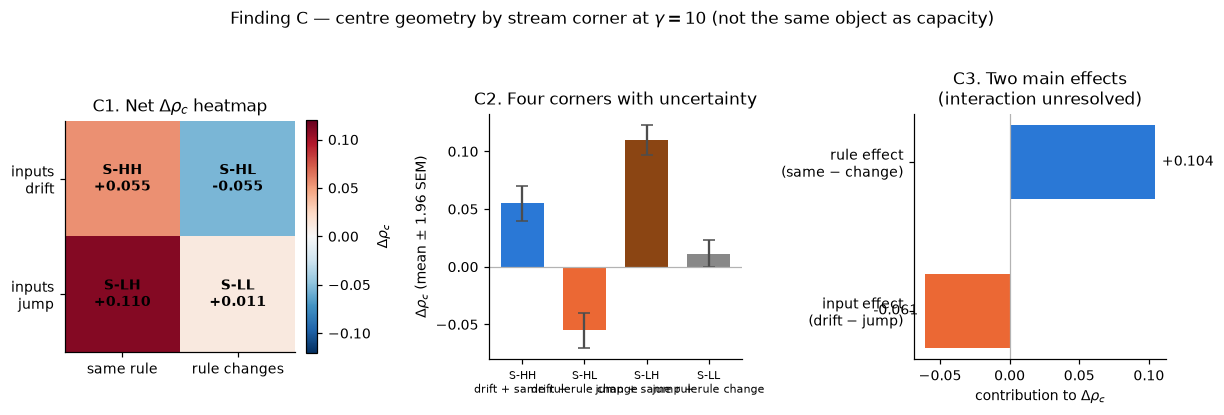

In [12]:
cells_f2 = u8["fig4"]["10"]["cells"]
eff = u8["fig4"]["10"]["effects"]
inter_over = u8["fig4"]["10"]["interaction_over_sem_unique"]
corners = ("S-HH", "S-HL", "S-LH", "S-LL")
plain = {
    "S-HH": "drift + same rule",
    "S-HL": "drift + rule change",
    "S-LH": "jump + same rule",
    "S-LL": "jump + rule change",
}

print("=" * 72)
print("FINDING C — Delta rho_c (centre correlation), gamma=10")
print("=" * 72)
print()
print(f"{'corner':<8} {'plain language':<22} {'Δρ_c':>9} {'SEM':>8} "
      f"{'declining':>10} {'sign-test p':>12}")
for c in corners:
    d = cells_f2[c]
    print(f"{c:<8} {plain[c]:<22} {d['delta_mean']:+9.4f} {d['sem_unique']:8.4f} "
          f"{d['n_declining_unique']:>3}/{d['n_unique']:<4} {d['p_unique']:12.3g}")

print()
print("Main effects (mean of high minus mean of low on each axis):")
print(f"  rule axis (same minus change)  : {eff['readout']:+.4f}  -> same rule => more convergence")
print(f"  input axis (drift minus jump)  : {eff['feature']:+.4f}  -> drift => more decorrelation than jump")
status = "unresolved" if abs(inter_over) < 2 else "resolvable"
print(f"  interaction                    : {eff['interaction']:+.4f}  {status} "
      f"({inter_over:.2f} x unique SEM)")
print()
print("Predicted catastrophic corner S-HL: decorrelates (sign OK).")
print("Largest centre displacement is S-LH (convergence), not S-HL.")

fig, axes = plt.subplots(1, 3, figsize=(11.2, 3.6))

# C1 — heatmap with plain-language ticks
ax = axes[0]
mat = np.array([
    [cells_f2["S-HH"]["delta_mean"], cells_f2["S-HL"]["delta_mean"]],
    [cells_f2["S-LH"]["delta_mean"], cells_f2["S-LL"]["delta_mean"]],
])
im = ax.imshow(mat, cmap="RdBu_r", vmin=-0.12, vmax=0.12)
ax.set_xticks([0, 1], ["same rule", "rule changes"])
ax.set_yticks([0, 1], ["inputs\ndrift", "inputs\njump"])
for i, row_cs in enumerate((("S-HH", "S-HL"), ("S-LH", "S-LL"))):
    for j, c in enumerate(row_cs):
        val = cells_f2[c]["delta_mean"]
        ax.text(j, i, f"{c}\n{val:+.3f}", ha="center", va="center",
                color="k", fontsize=9, fontweight="bold")
ax.set_title(r"C1. Net $\Delta\rho_c$ heatmap")
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04, label=r"$\Delta\rho_c$")

# C2 — bars with SEM error bars
ax = axes[1]
means = [cells_f2[c]["delta_mean"] for c in corners]
sems = [cells_f2[c]["sem_unique"] for c in corners]
x = np.arange(len(corners))
bar_colors = ["#2a78d6", "#eb6834", "#8B4513", "#888888"]
ax.bar(x, means, yerr=1.96 * np.array(sems), color=bar_colors, width=0.7,
       capsize=4, ecolor="0.3")
ax.axhline(0, color="0.7", lw=0.8)
ax.set_xticks(x, [f"{c}\n{plain[c]}" for c in corners], fontsize=7)
ax.set_ylabel(r"$\Delta\rho_c$ (mean $\pm$ 1.96 SEM)")
ax.set_title("C2. Four corners with uncertainty")

# C3 — main effects as two arrows / bars
ax = axes[2]
ax.barh([1, 0], [eff["readout"], eff["feature"]],
        color=["#2a78d6", "#eb6834"], height=0.5)
ax.axvline(0, color="0.7", lw=0.8)
ax.set_yticks([1, 0], ["rule effect\n(same − change)", "input effect\n(drift − jump)"])
ax.set_xlabel(r"contribution to $\Delta\rho_c$")
ax.set_title("C3. Two main effects\n(interaction unresolved)")
for y, v in zip([1, 0], [eff["readout"], eff["feature"]]):
    ax.text(v + (0.005 if v >= 0 else -0.005), y, f"{v:+.3f}",
            va="center", ha="left" if v >= 0 else "right", fontsize=9)

fig.suptitle(
    r"Finding C — centre geometry by stream corner at $\gamma=10$ "
    r"(not the same object as capacity)",
    fontsize=11, y=1.03,
)
plt.tight_layout()
plt.show()


**Takeaway for Finding C.** Which stream you run changes whether class centres
converge or decorrelate. The empirically “worst” centre-decorrelating corner is
S-HL; the largest centre *motion* is S-LH. That splits the old catastrophic-corner
story: capacity loss, centre decorrelation, and centre displacement are related
but not interchangeable.


### Finding D (brief) — The predicted generic↓ / retained↑ trade did not appear

Both rise with $\gamma$; there is no crossing that locates a behavioural optimum.
Treat as a registered negative, not a positive theory of stability–plasticity.
Details: `docs/07`, `docs/14`.


## 9. What these numbers are allowed to mean

1. **Synthetic, shallow, linearly readable.** One ReLU layer over nearly separable centres; capacity is linear-readout geometry, not “all of forgetting.”
2. **Matched loss, not matched compute.** Rich arms take fewer steps.
3. **One co-designed learner.** MSE + full-batch GD + μP. Attempts to swap CE or Adam hit operating-point failures (`docs/07` §A.9).
4. **Consecutive ≠ lag-12 similarity.** A stream labelled “high $s_f$” only sets the *step* correlation; by lag 12 the realised correlation to task 0 is much lower (~0.28).

Full record of sampling units, corrections, and claim tiers: `docs/14-claim-security.md`, `docs/15-what-was-actually-run.md`, `results/LOG.md`.


## 10. Where it goes (for ICML)

Priority verification: corrected learning-rate law at $L=2$; order arm (pre-committed); stream-language rewrite in paper prose; naturalistic confirmation. Depth / modularity only after the LR law is settled.

Open question for the room: can the “content was never scarce” constraint be stated as a prediction that depth would test?
